# 🚀 IBM Applied Data Science Capstone — SpaceX Launch Records Dashboard
## Laboratoire complet : *Build an Interactive Dashboard with Plotly Dash*

**Source principale :** document IBM *Hands-on Lab: Build an Interactive Dashboard with Plotly Dash* (PDF de 22 pages fourni).  
**Environnement :** JupyterLab Desktop sur macOS, noyau **Python 3 (ipykernel)**.  
**Livrable :** ce fichier `.ipynb`, comprenant toutes les instructions exécutables et le tableau de bord Dash, **sans Terminal macOS et sans fichier `.py` séparé**.

### Objectifs IBM (respect de l'ordre du PDF)
1. **TASK 1 :** sélectionner un site avec `dcc.Dropdown` (pages 5–6).
2. **TASK 2 :** faire varier un **pie chart** selon le site choisi (pages 6–8).
3. **TASK 3 :** filtrer les masses utiles avec `dcc.RangeSlider`, de **0 à 10 000 kg** par pas de 1 000 kg (pages 8–9).
4. **TASK 4 :** faire varier un **scatter chart** selon le site et la charge utile, coloré par type de booster (pages 9–10 et 20–21).
5. **Questions IBM :** cinq analyses chiffrées et reproductibles (pages 2 et 21).

> **Mode d'emploi.** Commence **en haut**. Exécute chaque cellule de code en descendant, avec `Shift + Enter`. Les cellules de texte ne nécessitent aucune action. La **toute dernière cellule** démarre le dashboard. **Ne clique pas sur « Run All » deux fois** : deux serveurs sur le port 8050 entreraient en conflit.

> **Données :** nous travaillons bien sur le CSV `spacex_launch_dash.csv` prévu par le laboratoire IBM, et non sur le CSV de l'ancien laboratoire API, dont les colonnes sont différentes. Aucun chiffre n'est inventé.

## Étape 1 — Préparer JupyterLab (PDF, page 3)

Le PDF utilise un terminal Cloud IDE. **Chez toi, on remplace cette étape par `%pip` dans le notebook**, afin d'installer les bibliothèques dans le même Python que ton noyau JupyterLab. `Dash >= 2.11` permet de faire tourner une application directement dans un notebook JupyterLab.

Exécute la cellule suivante **une seule fois**. Si JupyterLab demande de redémarrer le noyau après l'installation, fais-le puis reprends depuis le début.

In [1]:
%pip install -q "dash>=2.11" pandas plotly requests

Note: you may need to restart the kernel to use updated packages.


### Étape 1 bis — Importer les bibliothèques et vérifier l'environnement

Ces imports doivent être effectués **avant** l'utilisation de `pd`, `px`, `dcc`, `html`, etc. Les versions affichées servent à diagnostiquer un éventuel problème de compatibilité.

In [2]:
import sys
from pathlib import Path
from io import BytesIO

import pandas as pd
import plotly
import plotly.express as px
import requests
import dash
from dash import Dash, dcc, html, Input, Output
from IPython.display import display

print('Python :', sys.version.split()[0])
print('JupyterLab travaille dans :', Path.cwd())
print('Pandas :', pd.__version__)
print('Plotly :', plotly.__version__)
print('Dash :', dash.__version__)
print('Environnement prêt.')

Python : 3.12.13
JupyterLab travaille dans : ~
Pandas : 2.2.3
Plotly : 7.0.0
Dash : 4.4.1
Environnement prêt.


## Étape 2 — Obtenir les données IBM (PDF, page 4)

Le laboratoire te fait télécharger `spacex_launch_dash.csv` avec `wget`. Dans **JupyterLab Desktop**, le code ci-dessous :

- utilise d'abord une copie locale du **bon CSV** si elle existe dans le même dossier que le notebook ;
- sinon effectue un **GET HTTP** sur l'URL du dataset IBM et sauvegarde la réponse ;
- vérifie le code HTTP, les colonnes et le contenu **avant** de les utiliser.

L'objectif reste celui d'IBM : **travailler avec le vrai jeu de données du dashboard**. Si l'URL IBM ne répond pas sur ton réseau, charge manuellement le fichier `spacex_launch_dash.csv` dans JupyterLab avec le bouton **Upload Files**, puis relance cette cellule. **N'utilise pas** `dataset_part_1.csv`, `dataset_part_2.csv` ou `spacex_source_dataset.csv` à sa place.

In [3]:
CSV_FILENAME = 'spacex_launch_dash.csv'
IBM_CSV_URL = (
    'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/'
    'IBM-DS0321EN-SkillsNetwork/datasets/spacex_launch_dash.csv'
)
CSV_PATH = Path(CSV_FILENAME)
required_columns = {
    'Flight Number', 'Launch Site', 'class',
    'Payload Mass (kg)', 'Booster Version Category'
}

if CSV_PATH.exists():
    print('Lecture du CSV IBM local :', CSV_PATH.resolve())
    spacex_df = pd.read_csv(CSV_PATH)
else:
    print('Téléchargement du CSV depuis IBM...')
    try:
        response = requests.get(IBM_CSV_URL, timeout=30)
        response.raise_for_status()
        candidate_df = pd.read_csv(BytesIO(response.content))
        missing_columns = required_columns - set(candidate_df.columns)
        if missing_columns:
            raise ValueError(f'Le fichier téléchargé ne contient pas : {sorted(missing_columns)}')
        if candidate_df.empty:
            raise ValueError('Le CSV IBM téléchargé est vide.')
        CSV_PATH.write_bytes(response.content)
        spacex_df = candidate_df
        print('GET HTTP :', response.status_code, '| Fichier sauvegardé :', CSV_PATH.resolve())
    except Exception as exc:
        raise RuntimeError(
            'Le téléchargement du CSV IBM a échoué. Ouvre le lien IBM indiqué '
            'dans IBM_CSV_URL, télécharge spacex_launch_dash.csv, puis utilise '
            'Upload Files dans JupyterLab avant de relancer cette cellule. '
            f'Erreur technique : {type(exc).__name__} : {exc}'
        ) from exc

missing_columns = required_columns - set(spacex_df.columns)
if missing_columns:
    raise ValueError(
        f"Ce CSV n'est pas celui du dashboard IBM. Colonnes manquantes : {sorted(missing_columns)}. "
        f'Colonnes présentes : {list(spacex_df.columns)}'
    )

print('Dimensions (lancements, colonnes) :', spacex_df.shape)
print('Colonnes :', spacex_df.columns.tolist())
display(spacex_df.head(5))

Lecture du CSV IBM local : ~/spacex_launch_dash.csv
Dimensions (lancements, colonnes) : (56, 8)
Colonnes : ['Unnamed: 0', 'Flight Number', 'Launch Site', 'Mission Outcome', 'class', 'Payload Mass (kg)', 'Booster Version', 'Booster Version Category']


,Unnamed: 0,Flight Number,Launch Site,Mission Outcome,class,Payload Mass (kg),Booster Version,Booster Version Category
0,0,1,CCAFS LC-40,Success,0,0.0,F9 v1.0 B0003,v1.0
1,1,2,CCAFS LC-40,Success,0,0.0,F9 v1.0 B0004,v1.0
2,2,3,CCAFS LC-40,Success,0,525.0,F9 v1.0 B0005,v1.0
3,3,4,CCAFS LC-40,Success,0,500.0,F9 v1.0 B0006,v1.0
4,4,5,CCAFS LC-40,Success,0,677.0,F9 v1.0 B0007,v1.0


## Étape 3 — Comprendre et contrôler le dataset

Dans ce laboratoire, **une ligne représente un lancement**. Les variables nécessaires sont :

| Colonne | Signification pour IBM |
|---|---|
| `Flight Number` | Numéro du vol |
| `Launch Site` | Site de lancement |
| `class` | **1 : premier étage récupéré avec succès**, **0 : échec / pas d'atterrissage réussi** |
| `Payload Mass (kg)` | Masse de la charge utile en kilogrammes |
| `Booster Version Category` | Version générale du Falcon 9 : `v1.0`, `v1.1`, `FT`, `B4`, `B5`... |

**Attention :** `class` correspond à la réussite de la **récupération du premier étage** dans ce projet, pas nécessairement au succès de la mission spatiale.

Nous gardons la structure d'IBM, sans modifier ses catégories ni fabriquer de lignes.

In [4]:
# Conserver les noms de colonnes d'origine, utiles pour le quiz IBM.
spacex_df['class'] = pd.to_numeric(spacex_df['class'], errors='raise')
spacex_df['Payload Mass (kg)'] = pd.to_numeric(
    spacex_df['Payload Mass (kg)'], errors='raise'
)

print('Valeurs manquantes :')
display(spacex_df[list(required_columns)].isna().sum().to_frame('Manquants'))
print('Valeurs distinctes de class :', sorted(spacex_df['class'].dropna().unique().tolist()))
print('Noms des sites :', sorted(spacex_df['Launch Site'].dropna().unique().tolist()))
print('Catégories de boosters :', sorted(spacex_df['Booster Version Category'].dropna().unique().tolist()))

if not spacex_df['class'].dropna().isin([0, 1]).all():
    raise ValueError('La colonne class doit contenir uniquement 0 et 1.')

# Conserver pour les graphiques les lignes complètes, sans altérer le CSV brut.
dashboard_df = spacex_df.dropna(
    subset=['Launch Site', 'class', 'Payload Mass (kg)', 'Booster Version Category']
).copy()
dashboard_df['class'] = dashboard_df['class'].astype(int)

print('Nombre de lignes IBM :', len(spacex_df))
print('Lignes exploitables pour les graphiques :', len(dashboard_df))
print('Masse utile min / max :', dashboard_df['Payload Mass (kg)'].min(),
      '/', dashboard_df['Payload Mass (kg)'].max(), 'kg')

Valeurs manquantes :


,Manquants
Payload Mass (kg),0
Booster Version Category,0
class,0
Launch Site,0
Flight Number,0


Valeurs distinctes de class : [0, 1]
Noms des sites : ['CCAFS LC-40', 'CCAFS SLC-40', 'KSC LC-39A', 'VAFB SLC-4E']
Catégories de boosters : ['B4', 'B5', 'FT', 'v1.0', 'v1.1']
Nombre de lignes IBM : 56
Lignes exploitables pour les graphiques : 56
Masse utile min / max : 0.0 / 9600.0 kg


## Étape 4 — Définir l'application Dash, une seule fois

Nous allons construire le dashboard **progressivement, dans l'ordre IBM**, mais nous ne démarrerons le serveur qu'après avoir défini ses quatre composants et leurs callbacks. Ceci évite les `NameError` et les exécutions dans le désordre.

In [5]:
app = Dash(__name__)
app.title = 'SpaceX Launch Records Dashboard — IBM'
print('Application Dash initialisée. Nous allons maintenant ajouter les TASKS 1 à 4.')

Application Dash initialisée. Nous allons maintenant ajouter les TASKS 1 à 4.


## TASK 1 — Ajouter la liste déroulante des sites (PDF, pages 5–6)

**Exigences exactes IBM :**
- `id='site-dropdown'` ;
- une option spéciale `All Sites` dont la valeur est `'ALL'` ;
- tous les sites disponibles dans le CSV ;
- valeur initiale `'ALL'` ;
- texte indicatif (*placeholder*) et recherche activée.

La cellule ci-dessous **fabrique** le menu. Nous l'insérerons dans le dashboard à l'étape 8.

In [6]:
site_names = sorted(dashboard_df['Launch Site'].unique().tolist())
site_options = [{'label': 'All Sites', 'value': 'ALL'}] + [
    {'label': site, 'value': site} for site in site_names
]

site_dropdown = dcc.Dropdown(
    id='site-dropdown',
    options=site_options,
    value='ALL',
    placeholder='Select a Launch Site here',
    searchable=True,
    clearable=False
)

print('Options disponibles dans le menu :')
for option in site_options:
    print(f"  {option['label']}  →  {option['value']}")

Options disponibles dans le menu :
  All Sites  →  ALL
  CCAFS LC-40  →  CCAFS LC-40
  CCAFS SLC-40  →  CCAFS SLC-40
  KSC LC-39A  →  KSC LC-39A
  VAFB SLC-4E  →  VAFB SLC-4E


## TASK 2 — Programmer le **pie chart** et le callback (PDF, pages 6–8)

Un **callback** recalcule le graphique quand l'utilisateur choisit un site :

- **ALL** : chaque secteur représente le **nombre de récupérations réussies** (`class == 1`) sur un site.
- **Un site spécifique** : deux secteurs comparent les vols `class == 1` et `class == 0` pour **ce site**.

Le graphique doit porter l'identifiant IBM `success-pie-chart` et être relié au menu `site-dropdown`.

TASK 2 OK : graphique pour ALL.


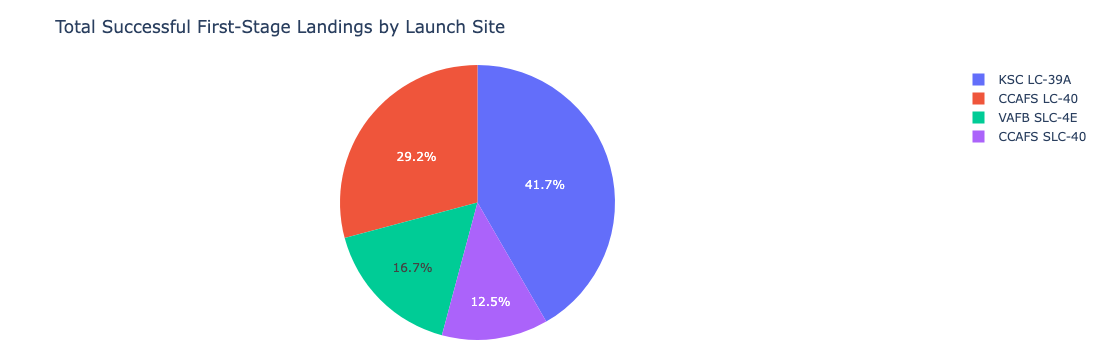

In [7]:
@app.callback(
    Output(component_id='success-pie-chart', component_property='figure'),
    Input(component_id='site-dropdown', component_property='value')
)
def get_pie_chart(entered_site):
    if entered_site == 'ALL':
        # Chaque site : seulement les atterrissages réussis (class == 1).
        successes = (
            dashboard_df.loc[dashboard_df['class'] == 1]
            .groupby('Launch Site').size()
            .reset_index(name='Successful landings')
        )
        fig = px.pie(
            successes,
            values='Successful landings',
            names='Launch Site',
            title='Total Successful First-Stage Landings by Launch Site',
            hole=0
        )
    else:
        # Pour un site particulier : 1 (succès) versus 0 (échec).
        filtered = dashboard_df[dashboard_df['Launch Site'] == entered_site]
        counts = (
            filtered['class']
            .value_counts()
            .reindex([0, 1], fill_value=0)
            .rename_axis('class')
            .reset_index(name='Count')
        )
        counts['Outcome'] = counts['class'].map({0: 'Failed landing', 1: 'Successful landing'})
        fig = px.pie(
            counts,
            values='Count',
            names='Outcome',
            title=f'Landing Outcomes for {entered_site}',
            color='Outcome',
            color_discrete_map={
                'Successful landing': '#269e71',
                'Failed landing': '#d75b5b'
            }
        )
    fig.update_layout(margin=dict(t=65, l=15, r=15, b=20))
    return fig

# Vérification sans lancer le serveur : chaque callback est bien défini.
print('TASK 2 OK : graphique pour ALL.')
get_pie_chart('ALL').show()

### Contrôle IBM — Observer un site particulier

Cette prévisualisation **ne remplace pas le callback** : elle permet seulement de vérifier le résultat avant de créer la page Dash. Le menu interactif fonctionnera à la dernière étape.

Exemple de site : CCAFS LC-40


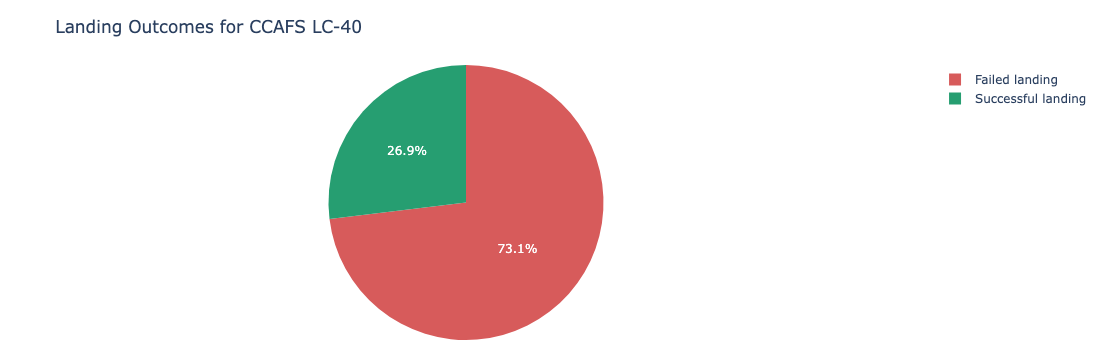

In [8]:
selected_example_site = site_names[0]
print('Exemple de site :', selected_example_site)
get_pie_chart(selected_example_site).show()

## TASK 3 — Ajouter le Range Slider (PDF, pages 8–9)

**Exigences exactes IBM :** `id='payload-slider'`, `min=0`, `max=10000`, `step=1000`, `value=[0,10000]`.

Les valeurs sélectionnées seront utilisées pour filtrer les lancements selon leur masse utile, **en kg**. Le filtre inclut les limites de la plage choisie.

In [9]:
min_payload = 0
max_payload = 10000

payload_slider = dcc.RangeSlider(
    id='payload-slider',
    min=min_payload,
    max=max_payload,
    step=1000,
    value=[min_payload, max_payload],
    marks={i: f'{i:,}'.replace(',', ' ') for i in range(0, 10001, 2000)},
    allowCross=False,
    tooltip={'placement': 'bottom', 'always_visible': True}
)
print('TASK 3 OK : slider', min_payload, '→', max_payload, 'kg, pas de 1 000 kg.')

TASK 3 OK : slider 0 → 10000 kg, pas de 1 000 kg.


## TASK 4 — Programmer le scatter chart et son callback (PDF, pages 9–10 / 20–21)

**Entrées IBM :** `site-dropdown` **et** `payload-slider`.  
**Sortie IBM :** `success-payload-scatter-chart`.  
**Axes IBM :** X = `Payload Mass (kg)`, Y = `class`, couleur = `Booster Version Category`.

Tous les points sont des lancements réels du CSV IBM. Le graphique change dès que l'un des deux filtres change.

TASK 4 OK : graphique de contrôle ALL / 0–10 000 kg.


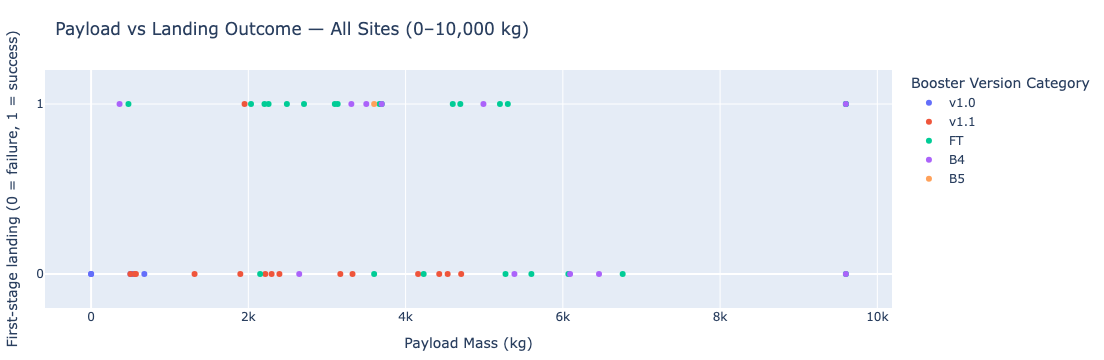

In [10]:
@app.callback(
    Output(component_id='success-payload-scatter-chart', component_property='figure'),
    Input(component_id='site-dropdown', component_property='value'),
    Input(component_id='payload-slider', component_property='value')
)
def get_scatter_chart(entered_site, payload_range):
    lower, upper = payload_range
    filtered = dashboard_df[
        dashboard_df['Payload Mass (kg)'].between(lower, upper, inclusive='both')
    ]

    if entered_site != 'ALL':
        filtered = filtered[filtered['Launch Site'] == entered_site]

    fig = px.scatter(
        filtered,
        x='Payload Mass (kg)',
        y='class',
        color='Booster Version Category',
        hover_data=['Launch Site', 'Flight Number'] if 'Flight Number' in filtered.columns else ['Launch Site'],
        title=(f'Payload vs Landing Outcome — '
               f'{"All Sites" if entered_site == "ALL" else entered_site} '
               f'({lower:,}–{upper:,} kg)'),
        labels={
            'class': 'First-stage landing (0 = failure, 1 = success)',
            'Payload Mass (kg)': 'Payload Mass (kg)'
        }
    )
    fig.update_yaxes(tickmode='array', tickvals=[0, 1], range=[-0.20, 1.20])
    fig.update_layout(margin=dict(t=70, l=35, r=20, b=30))
    return fig

# Test direct du callback. Les 2 filtres sont déjà opérationnels.
print('TASK 4 OK : graphique de contrôle ALL / 0–10 000 kg.')
get_scatter_chart('ALL', [0, 10000]).show()

## Étape 5 — Construire le dashboard avec les quatre tâches IBM

Tous les objets existent désormais : `app`, `site_dropdown`, `payload_slider`, et les deux callbacks. Nous pouvons les placer **ensemble** sur une page.

Aucun serveur n'est encore lancé : nous réservons cela à la **dernière cellule**.

In [11]:
app.layout = html.Div([
    html.H1(
        'SpaceX Launch Records Dashboard',
        style={'textAlign': 'center', 'color': '#162b48', 'marginBottom': '8px'}
    ),
    html.P(
        'IBM Applied Data Science Capstone | Interactive Visual Analytics',
        style={'textAlign': 'center', 'color': '#64748b', 'marginBottom': '24px'}
    ),
    html.Label('Select a Launch Site (TASK 1)', style={'fontWeight': 'bold'}),
    site_dropdown,
    html.Div([
        dcc.Graph(id='success-pie-chart')
    ], style={'marginTop': '18px'}),
    html.Label('Select Payload Range (kg) — TASK 3', style={'fontWeight': 'bold'}),
    html.Div(payload_slider, style={'padding': '20px 12px 25px 12px'}),
    dcc.Graph(id='success-payload-scatter-chart'),
    html.P(
        'class = 1 : successful first-stage landing | class = 0 : no successful landing',
        style={'color': '#64748b', 'textAlign': 'center', 'fontSize': '13px'}
    )
], style={
    'fontFamily': 'Arial, sans-serif',
    'maxWidth': '1100px', 'margin': '0 auto', 'padding': '28px 25px',
    'backgroundColor': '#ffffff'
})

print('Dashboard construit : dropdown + pie chart + slider + scatter chart.')
print('Callbacks enregistrés :', list(app.callback_map))
assert 'success-pie-chart.figure' in app.callback_map
assert 'success-payload-scatter-chart.figure' in app.callback_map

Dashboard construit : dropdown + pie chart + slider + scatter chart.
Callbacks enregistrés : ['success-pie-chart.figure', 'success-payload-scatter-chart.figure']


# Finding Insights Visually — Les cinq questions officielles IBM

Cette partie répond à la section **« Finding Insights Visually »** du PDF (pages 2 et 21). Contrairement à une simple impression visuelle, nous allons **calculer les effectifs et les pourcentages** directement à partir du CSV IBM chargé.

**Rappel statistique :** `taux de réussite = nombre de class=1 / nombre de lancements`. Un site qui a *le plus de réussites en nombre* n'est pas nécessairement celui qui a *le meilleur pourcentage*.

**Important :** les questions 3 et 4 (« payload range(s) ») ne définissent pas d'intervalles numériques uniques dans le PDF. Nous choisissons explicitement des tranches de **1 000 kg**, cohérentes avec le pas du slider, et indiquons toujours la taille des groupes. Un groupe de 1 lancement ne constitue pas une preuve solide d'une supériorité réelle.

## Question IBM 1 — Quel site possède le plus grand **nombre** d'atterrissages réussis ?

IBM : *Which site has the largest successful launches?*  
Méthode : `groupby('Launch Site')`, puis `sum()` de la colonne binaire `class`.

In [12]:
site_stats = (
    dashboard_df.groupby('Launch Site')['class']
    .agg(Launches='size', SuccessfulLandings='sum', SuccessRate='mean')
    .sort_values(['SuccessfulLandings', 'SuccessRate'], ascending=False)
)
site_stats['SuccessRatePercent'] = (100 * site_stats['SuccessRate']).round(2)
display(site_stats)

max_count = site_stats['SuccessfulLandings'].max()
max_sites = site_stats.index[site_stats['SuccessfulLandings'] == max_count].tolist()
print('RÉPONSE QUESTION 1 :', ', '.join(max_sites), '|', int(max_count), 'réussites.')

,Launches,SuccessfulLandings,SuccessRate,SuccessRatePercent
Launch Site,,,,
KSC LC-39A,13,10,0.769231,76.92
CCAFS LC-40,26,7,0.269231,26.92
VAFB SLC-4E,10,4,0.400000,40.00
CCAFS SLC-40,7,3,0.428571,42.86


RÉPONSE QUESTION 1 : KSC LC-39A | 10 réussites.


## Question IBM 2 — Quel site a le plus haut **taux** d'atterrissage réussi ?

IBM : *Which site has the highest launch success rate?*  
Méthode : `mean()` de la variable binaire `class` par site. Une valeur moyenne de `0.75` signifie **75 %**.

In [13]:
site_by_rate = site_stats.sort_values(
    ['SuccessRate', 'Launches'], ascending=False
)
display(site_by_rate[['Launches', 'SuccessfulLandings', 'SuccessRatePercent']])

max_rate = site_by_rate['SuccessRate'].max()
best_rate_sites = site_by_rate.index[
    (site_by_rate['SuccessRate'] - max_rate).abs() < 1e-12
].tolist()
print('RÉPONSE QUESTION 2 :', ', '.join(best_rate_sites),
      '| taux =', f'{max_rate:.2%}')

,Launches,SuccessfulLandings,SuccessRatePercent
Launch Site,,,
KSC LC-39A,13,10,76.92
CCAFS SLC-40,7,3,42.86
VAFB SLC-4E,10,4,40.00
CCAFS LC-40,26,7,26.92


RÉPONSE QUESTION 2 : KSC LC-39A | taux = 76.92%


## Questions IBM 3 et 4 — Quelles plages de masse utile réussissent le plus et le moins ?

IBM : *Which payload range(s) has the highest / lowest launch success rate?*

- Nous étudions **0 à 10 000 kg**, parce que c'est exactement la plage prévue par le slider IBM.
- Nous découpons cette plage en intervalles de **1 000 kg**, sans en inventer les résultats.
- Nous affichons pour chaque intervalle **vols, succès, taux (%)**.
- Un lancement de masse exactement 10 000 kg est inclus dans le dernier intervalle.

In [14]:
import numpy as np

payload_df = dashboard_df[
    dashboard_df['Payload Mass (kg)'].between(0, 10000, inclusive='both')
].copy()

bin_edges = list(range(0, 10001, 1000))
payload_df['PayloadBracket'] = pd.cut(
    payload_df['Payload Mass (kg)'],
    bins=bin_edges, right=False, include_lowest=True
)

# 10000 kg serait exclu de [9000,10000[ : le placer dans le dernier groupe.
exact_upper_limit = payload_df['Payload Mass (kg)'] == 10000
if exact_upper_limit.any():
    last_category = payload_df['PayloadBracket'].cat.categories[-1]
    payload_df.loc[exact_upper_limit, 'PayloadBracket'] = last_category

payload_stats = (
    payload_df.groupby('PayloadBracket', observed=True)['class']
    .agg(Launches='size', SuccessfulLandings='sum', SuccessRate='mean')
    .sort_index()
)
payload_stats['SuccessRatePercent'] = (payload_stats['SuccessRate'] * 100).round(2)
payload_stats.index = payload_stats.index.map(lambda x: f'{int(x.left):,} à {int(x.right):,} kg'.replace(',', ' '))

display(payload_stats[['Launches', 'SuccessfulLandings', 'SuccessRatePercent']])
if payload_stats.empty:
    raise ValueError('Aucune charge utile dans la plage 0–10 000 kg : contrôler le CSV.')

max_payload_rate = payload_stats['SuccessRate'].max()
min_payload_rate = payload_stats['SuccessRate'].min()
best_payload_ranges = payload_stats.index[
    (payload_stats['SuccessRate'] - max_payload_rate).abs() < 1e-12
].tolist()
worst_payload_ranges = payload_stats.index[
    (payload_stats['SuccessRate'] - min_payload_rate).abs() < 1e-12
].tolist()

print('RÉPONSE QUESTION 3 (meilleur taux) :', ', '.join(best_payload_ranges),
      '|', f'{max_payload_rate:.2%}')
print('RÉPONSE QUESTION 4 (plus faible taux) :', ', '.join(worst_payload_ranges),
      '|', f'{min_payload_rate:.2%}')
print('NOTE : comparer aussi le nombre de lancements avant de tirer une conclusion.')

,Launches,SuccessfulLandings,SuccessRatePercent
PayloadBracket,,,
0 à 1 000 kg,10,2,20.00
1 000 à 2 000 kg,3,1,33.33
2 000 à 3 000 kg,10,5,50.00
3 000 à 4 000 kg,11,8,72.73
4 000 à 5 000 kg,8,3,37.50
5 000 à 6 000 kg,5,2,40.00
6 000 à 7 000 kg,4,0,0.00
9 000 à 10 000 kg,5,3,60.00


RÉPONSE QUESTION 3 (meilleur taux) : 3 000 à 4 000 kg | 72.73%
RÉPONSE QUESTION 4 (plus faible taux) : 6 000 à 7 000 kg | 0.00%
NOTE : comparer aussi le nombre de lancements avant de tirer une conclusion.


### Vérification visuelle supplémentaire : taux de réussite selon la charge utile

Ce graphique **complète** les deux graphiques obligatoires du dashboard. Il permet de justifier les réponses 3 et 4 au quiz sans se fier uniquement à une impression visuelle.

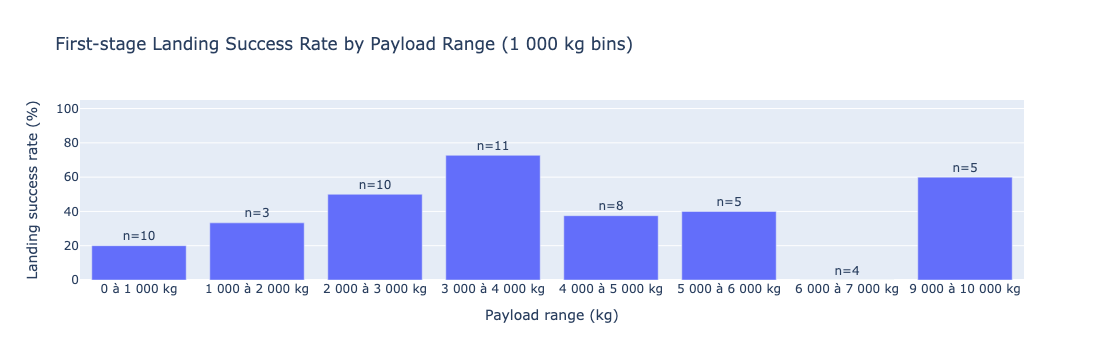

In [15]:
fig_payload_rates = px.bar(
    payload_stats.reset_index(),
    x='PayloadBracket', y='SuccessRatePercent',
    text='Launches',
    labels={
        'PayloadBracket': 'Payload range (kg)',
        'SuccessRatePercent': 'Landing success rate (%)',
        'Launches': 'Number of launches'
    },
    title='First-stage Landing Success Rate by Payload Range (1 000 kg bins)'
)
fig_payload_rates.update_yaxes(range=[0, 105])
fig_payload_rates.update_traces(texttemplate='n=%{text}', textposition='outside')
fig_payload_rates.show()

## Question IBM 5 — Quelle catégorie de booster Falcon 9 présente le meilleur taux ?

IBM : *Which F9 Booster version (v1.0, v1.1, FT, B4, B5, etc.) has the highest launch success rate?*  
Méthode : calculer le taux moyen de `class` par `Booster Version Category` et regarder les effectifs pour chaque catégorie. Les éventuels ex aequo sont tous présentés.

In [16]:
booster_stats = (
    dashboard_df.groupby('Booster Version Category')['class']
    .agg(Launches='size', SuccessfulLandings='sum', SuccessRate='mean')
    .sort_values(['SuccessRate', 'Launches'], ascending=False)
)
booster_stats['SuccessRatePercent'] = (100 * booster_stats['SuccessRate']).round(2)
display(booster_stats[['Launches', 'SuccessfulLandings', 'SuccessRatePercent']])

best_booster_rate = booster_stats['SuccessRate'].max()
best_boosters = booster_stats.index[
    (booster_stats['SuccessRate'] - best_booster_rate).abs() < 1e-12
].tolist()
print('RÉPONSE QUESTION 5 :', ', '.join(best_boosters),
      '| taux =', f'{best_booster_rate:.2%}')

,Launches,SuccessfulLandings,SuccessRatePercent
Booster Version Category,,,
B5,1,1,100.00
FT,24,16,66.67
B4,11,6,54.55
v1.1,15,1,6.67
v1.0,5,0,0.00


RÉPONSE QUESTION 5 : B5 | taux = 100.00%


## Récapitulatif automatique des cinq réponses IBM

**Cette cellule est particulièrement importante pour le quiz.** Elle reprend les conclusions dérivées **du fichier téléchargé**, ainsi que les définitions exactes des indicateurs.

In [17]:
quiz_answers = pd.DataFrame([
    {'Question': 1, 'Demande IBM': 'Site avec le plus de succès (nombre)',
     'Réponse calculée': ', '.join(max_sites),
     'Résultat': f'{int(max_count)} réussites'},
    {'Question': 2, 'Demande IBM': 'Site avec le plus haut taux de succès',
     'Réponse calculée': ', '.join(best_rate_sites),
     'Résultat': f'{max_rate:.2%}'},
    {'Question': 3, 'Demande IBM': 'Plage(s) de masse au meilleur taux',
     'Réponse calculée': ', '.join(best_payload_ranges),
     'Résultat': f'{max_payload_rate:.2%}'},
    {'Question': 4, 'Demande IBM': 'Plage(s) de masse au taux le plus faible',
     'Réponse calculée': ', '.join(worst_payload_ranges),
     'Résultat': f'{min_payload_rate:.2%}'},
    {'Question': 5, 'Demande IBM': 'Version(s) de booster au plus haut taux',
     'Réponse calculée': ', '.join(best_boosters),
     'Résultat': f'{best_booster_rate:.2%}'},
])
print('RÉPONSES IBM (calculées, non inventées) :')
display(quiz_answers)

RÉPONSES IBM (calculées, non inventées) :


,Question,Demande IBM,Réponse calculée,Résultat
0,1,Site avec le plus de succès (nombre),KSC LC-39A,10 réussites
1,2,Site avec le plus haut taux de succès,KSC LC-39A,76.92%
2,3,Plage(s) de masse au meilleur taux,3 000 à 4 000 kg,72.73%
3,4,Plage(s) de masse au taux le plus faible,6 000 à 7 000 kg,0.00%
4,5,Version(s) de booster au plus haut taux,B5,100.00%


## Étape 6 — Tests avant le lancement (aucun Terminal requis)

Nous vérifions que **tous** les widgets et les deux callbacks sont présents, que le dataset est cohérent et que les graphiques peuvent être calculés. Si une assertion échoue, elle permet de diagnostiquer le problème **avant** le démarrage du serveur.

In [18]:
assert len(site_names) == dashboard_df['Launch Site'].nunique()
assert site_options[0] == {'label': 'All Sites', 'value': 'ALL'}
assert set(dashboard_df['class'].unique()).issubset({0, 1})
assert len(quiz_answers) == 5
assert 'success-pie-chart.figure' in app.callback_map
assert 'success-payload-scatter-chart.figure' in app.callback_map
assert len(get_scatter_chart('ALL', [0, 10000]).data) > 0
assert len(get_pie_chart('ALL').data) > 0
assert len(get_pie_chart(site_names[0]).data) > 0

print('✓ CSV IBM validé')
print('✓ TASK 1 : site-dropdown')
print('✓ TASK 2 : callback pie chart')
print('✓ TASK 3 : payload-slider 0–10 000 kg')
print('✓ TASK 4 : callback scatter chart')
print('✓ Questions du quiz 1–5 calculées')
print('✓ Prêt à démarrer Dash dans JupyterLab')

✓ CSV IBM validé
✓ TASK 1 : site-dropdown
✓ TASK 2 : callback pie chart
✓ TASK 3 : payload-slider 0–10 000 kg
✓ TASK 4 : callback scatter chart
✓ Questions du quiz 1–5 calculées
✓ Prêt à démarrer Dash dans JupyterLab


## Étape 7 — Captures d'écran demandées par IBM (PDF, page 1)

Une fois le dashboard ouvert, pense à réaliser **des captures d'écran** :

1. `All Sites` : le diagramme circulaire du nombre de récupérations réussies par site ;
2. sélection d'un site : le diagramme circulaire `Successful landing` / `Failed landing` ;
3. slider **0–10 000 kg** puis plage plus étroite : variation du scatter chart ;
4. une vue où les **catégories de booster** sont visibles dans la légende.

Sur Mac, utilise **⇧⌘4** pour sélectionner une zone. Garde les captures pour ton **rapport PowerPoint/PDF final**. IBM te demande également de conserver ton notebook sur GitHub ; il faudra le publier toi-même lorsque les tests seront terminés.

**Important pour l'exercice :** les taux de réussite sont des proportions issues du jeu de données IBM historique. Ne les confonds pas avec les performances récentes de SpaceX.

## Étape 8 — **Démarrer le dashboard depuis JupyterLab** (sans Terminal Mac)

Exécute la cellule ci-dessous **en dernier**. Dash affiche un lien ; ouvre-le dans ton navigateur Mac : **http://127.0.0.1:8050/**.

- Elle lance une véritable application Dash avec ses **deux callbacks** interactifs.
- Dans Dash ≥2.11, le mode `jupyter_mode='external'` lance le serveur local pour un notebook JupyterLab et affiche son adresse. **Tu n'as pas besoin de lancer un `.py` dans Terminal.**
- Laisse JupyterLab ouvert pendant tes essais. Si le port **8050** est déjà utilisé par une autre application, modifie **seulement** `port=8050` en `port=8051`, puis ouvre `http://127.0.0.1:8051/`.
- **Ne relance pas cette cellule** si le serveur est déjà démarré. Tu peux modifier les graphiques en interagissant avec le dropdown et le slider directement sur la page.

> ⚠️ La dernière cellule démarre un service **local**. Elle n'a volontairement pas été pré-exécutée dans le fichier livré ; tu la lances toi-même sur ton Mac, après les cellules précédentes.

In [19]:
# Dernière cellule : démarrer les 4 tâches interactives du laboratoire IBM.
print('Ouverture du dashboard : http://127.0.0.1:8050/')
app.run(
    jupyter_mode='external',
    host='127.0.0.1',
    port=8050,
    debug=False,
    use_reloader=False
)

Ouverture du dashboard : http://127.0.0.1:8050/
Dash app running on http://127.0.0.1:8050/
